In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [ ]:
df = pd.read_csv('data.csv')
#Just to make the index start from 1
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
#Count the features that have no difference at all in all data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

1

In [ ]:
#Find the index of feature which have no difference at all
np.min(np.std(X,axis=0)), np.where(np.std(X,axis=0)==0), np.argmin(np.std(X,axis=0))

(0.0, (array([93]),), 93)

In [ ]:
check_feature_name_with_sd_0=[]

In [ ]:
for i in range(np.shape(np.where(np.std(X,axis=0)==0))[0]):
  print(pd.read_csv('data.csv').columns.tolist()[(list(np.where(np.std(X,axis=0)==0)[i])[0])])

 Interest Coverage Ratio (Interest expense to EBIT)


In [ ]:
X=np.delete(X,list(np.where(np.std(X,axis=0)==0)),axis=1)

In [ ]:
#Count the features that have no difference at all in all data after deleting the data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

0

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 94), (4636,), (1364, 94), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 94), (819,))

In [ ]:
np.shape(np.mean(X_train,axis=0))

(94,)

In [ ]:
np.count_nonzero(np.std(X,axis=0))

94

In [ ]:
mean=np.copy(np.mean(X_train,axis=0))
std=np.copy(np.std(X_train,axis=0))

In [ ]:
X_train_rescale=(X_train-mean)/(std)

In [ ]:
X_train_rescale

array([[ 1.90296242,  1.75119366,  1.86826578, ..., -0.04482293,
        -0.0121836 , -0.42214359],
       [ 0.6281232 ,  0.28436509,  0.77600121, ..., -0.0377838 ,
         0.03174293, -0.38983898],
       [-0.09873029, -0.31695914, -0.10257863, ..., -0.02571204,
         0.08874173, -0.36849753],
       ...,
       [ 0.01346857,  0.23656108,  0.0457645 , ..., -0.03814377,
         0.02972356, -0.33827418],
       [-0.49061327, -0.26663912, -0.43193569, ..., -0.03723269,
         0.03479245, -0.30907101],
       [ 0.35087819,  0.39506914,  0.47489998, ..., -0.04117001,
         0.0118357 , -0.29664792]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_rescale).all()

True

In [ ]:
X_train_new_rescale=np.copy(X_train_rescale[(abs(X_train_rescale)<3.5).all(axis=1)])
#Even y_train_new_rescale is called y_train_new_rescale, we did not rescale it.
#We just remove the outliers according to X_train
y_train_new_rescale=np.copy(y_train[(abs(X_train_rescale)<3.5).all(axis=1)])

In [ ]:
np.shape(X_train_new_rescale), np.shape(y_train_new_rescale)

((3716, 94), (3716,))

In [ ]:
import sklearn
from sklearn import preprocessing

In [ ]:
X_train_new_rescale

array([[ 1.90296242,  1.75119366,  1.86826578, ..., -0.04482293,
        -0.0121836 , -0.42214359],
       [ 0.6281232 ,  0.28436509,  0.77600121, ..., -0.0377838 ,
         0.03174293, -0.38983898],
       [-0.37434923,  0.18959572, -0.16615425, ..., -0.04185517,
         0.00754484, -0.48319953],
       ...,
       [ 0.27282681,  0.2868811 ,  0.42192029, ..., -0.03737746,
         0.03399627,  0.00495448],
       [-0.49061327, -0.26663912, -0.43193569, ..., -0.03723269,
         0.03479245, -0.30907101],
       [ 0.35087819,  0.39506914,  0.47489998, ..., -0.04117001,
         0.0118357 , -0.29664792]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_new_rescale).all()

True

In [ ]:
y_train_new_rescale

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
#Show that not all the value are 0 in y_train_new_rescale
np.squeeze(np.argwhere(y_train_new_rescale==1))

array([   3,   31,   66,   95,  166,  176,  192,  280,  318,  366,  401,
        428,  451,  452,  467,  517,  537,  722,  738,  755,  763,  777,
        793,  812,  822,  840,  918,  926,  938, 1026, 1054, 1077, 1127,
       1138, 1146, 1188, 1267, 1300, 1385, 1389, 1414, 1450, 1547, 1616,
       1635, 1694, 1743, 1750, 1794, 1891, 1912, 1995, 2045, 2081, 2143,
       2150, 2167, 2178, 2236, 2317, 2363, 2455, 2504, 2535, 2592, 2601,
       2625, 2632, 2657, 2661, 2673, 2897, 2905, 2908, 2925, 2930, 2995,
       3029, 3053, 3072, 3164, 3252, 3308, 3374, 3387, 3407, 3424, 3437,
       3477, 3483, 3489, 3497, 3503, 3525, 3686, 3707])

In [ ]:
#Same rescaling in test dataset
X_test_rescale=(X_test-mean)/(std)
y_test_rescale=np.copy(y_test)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_test_rescale).all()

True

In [ ]:
#Same rescaling in validation set
X_train_val_rescale=(X_train_val-mean)/(std)
y_train_val_rescale=np.copy(y_train_val)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(y_train_val_rescale).all()

True

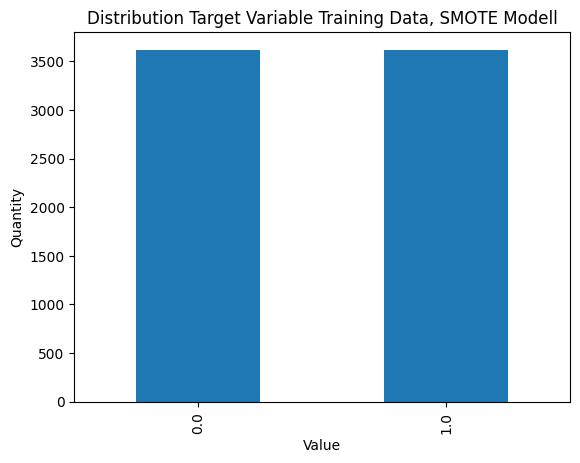

In [ ]:
#Oversampling: SMOTE Model
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_new_rescale, y_train_new_rescale)
y_resampled_series = pd.Series(y_resampled)

value_counts = y_resampled_series.value_counts()
value_counts.plot(kind="bar")
plt.title("Distribution Target Variable Training Data, SMOTE Modell")
plt.ylabel("Quantity")
plt.xlabel("Value")
plt.show()

In [ ]:
np.shape(X_resampled),np.shape(y_resampled),np.shape(X_test_rescale),np.shape(y_test_rescale)

((7240, 94), (7240,), (1364, 94), (1364,))

In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.model_selection import PredefinedSplit

In [ ]:
new_X_data=np.append(X_resampled, X_train_val_rescale,axis=0)

In [ ]:
np.shape(new_X_data)

(8059, 94)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_X_data[0:np.shape(X_resampled)[0]]==X_resampled).all()

True

In [ ]:
new_y_data=np.append(y_resampled, y_train_val_rescale,axis=0)

In [ ]:
np.shape(new_y_data)

(8059,)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_y_data[0:np.shape(y_resampled)[0]]==y_resampled).all()

True

In [ ]:
test_fold=[]

In [ ]:
#Next part is used to separate training set and validation set
#If we do not want to use data in that index as a validation set or testing set,
#set the value to be -1 for the index
#or else, set it as number larger or equal to 0,1,2,3.
#In this example, we only want to have four validation set
#which is the validation set we splitted out from
#the unprocessed training dataset.
#because we want the model applicable on the test dataset
#which is not being oversampled or outliers removed.
#We only use 0,1,2,3 which means we only train four times by using
#those data whose labels as 0,1,2,3 as the validation set
#Example is on the words next to this block

# >>> X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
# >>> y = np.array([0, 0, 1, 1])
# >>> test_fold = [0, 1, -1, 1]
# >>> ps = PredefinedSplit(test_fold)
# >>> ps.get_n_splits()
# 2
# >>> print(ps)
# PredefinedSplit(test_fold=array([ 0,  1, -1,  1]))
# >>> for i, (train_index, test_index) in enumerate(ps.split()):
# ...     print(f"Fold {i}:")
# ...     print(f"  Train: index={train_index}")
# ...     print(f"  Test:  index={test_index}")
# Fold 0:
#  Train: index=[1 2 3]
#  Test:  index=[0]
# Fold 1:
#  Train: index=[0 2]
#  Test:  index=[1 3]

In [ ]:
for i in range(np.shape(X_resampled)[0]):
  test_fold.append(-1)
j=0
for i in range(np.shape(X_train_val_rescale)[0]):
  test_fold.append(j)
  if j<3:
    j=j+1
  else:
    j=0

In [ ]:
ps = PredefinedSplit(test_fold=test_fold)

In [ ]:
depths = np.arange(5,10)
num_leafs = np.arange(7,11)
min_samples_leaf= np.arange(2,5)
min_samples_split=np.arange(2,4)

In [ ]:
try_grid = [{'max_depth':depths,
        'max_leaf_nodes':num_leafs,
        'min_samples_leaf':min_samples_leaf,
        'min_samples_split':min_samples_split}]

In [ ]:
#We want to use our own validation set
#See https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.PredefinedSplit.html#sklearn.model_selection.PredefinedSplit

In [ ]:
DTM = GridSearchCV(DecisionTreeClassifier(), param_grid=try_grid, cv=ps)

In [ ]:
#The code next line (DTM.fit(X_train, y_train)) could cost long time to work, please try only if you have
#time
#cv=ps already help us to split new_X_data and new_y_data into training set
# and validation set, that is why the input next line
# is new_X_data and new_y_data instead of X_resampled and y_resampled

In [ ]:
DTM.fit(new_X_data, new_y_data)

GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  1,  2])),
             estimator=DecisionTreeClassifier(),
             param_grid=[{'max_depth': array([5, 6, 7, 8, 9]),
                          'max_leaf_nodes': array([ 7,  8,  9, 10]),
                          'min_samples_leaf': array([2, 3, 4]),
                          'min_samples_split': array([2, 3])}])

In [ ]:
DTM.best_params_

{'max_depth': 5,
 'max_leaf_nodes': 10,
 'min_samples_leaf': 2,
 'min_samples_split': 2}

In [ ]:
DTM.best_score_

0.8802965088474415

In [ ]:
my_model=DecisionTreeClassifier(max_leaf_nodes=DTM.best_params_['max_leaf_nodes'],\
                max_depth=DTM.best_params_['max_depth'],\
                min_samples_leaf=DTM.best_params_['min_samples_leaf'],\
                min_samples_split=DTM.best_params_['min_samples_split'])

In [ ]:
my_model.fit(X_resampled, y_resampled)

DecisionTreeClassifier(max_depth=5, max_leaf_nodes=10, min_samples_leaf=2)

In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_resampled==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_resampled))

Non-bankrupted(value=0):  3620
Bankrupted(value=1):  3620


In [ ]:
# import evaluation tools for plotting the curve
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
#Check the cross-evaluation accuracy by using ROC
#Although it is not necessary

In [ ]:
tree_score = cross_val_score(my_model, X_resampled, y_resampled, cv=10)
print(tree_score.mean())

0.9029005524861878


In [ ]:
tree_preds = cross_val_predict(my_model, X_resampled, y_resampled, cv=10)

In [ ]:
print (f'This is prediction for decision tree: \n {tree_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 1. 1. 1.]


In [ ]:
np.count_nonzero(tree_preds==0),np.count_nonzero(tree_preds)

(3497, 3743)

In [ ]:
print(accuracy_score(y_resampled, tree_preds, normalize=True, sample_weight=None))

0.9029005524861878


In [ ]:
print(f'This is confusion matrix for decision tree: \n{confusion_matrix(y_resampled, tree_preds)}')

This is confusion matrix for decision tree: 
[[3207  413]
 [ 290 3330]]


In [ ]:
tree_preds_prob = cross_val_predict(my_model, X_resampled, y_resampled, cv=10, method="predict_proba")

In [ ]:
tree_preds_prob

array([[0.96530789, 0.03469211],
       [0.96530789, 0.03469211],
       [0.96530789, 0.03469211],
       ...,
       [0.07813571, 0.92186429],
       [0.07813571, 0.92186429],
       [0.07813571, 0.92186429]])

In [ ]:
tree_preds_prob_1 = cross_val_predict(my_model, X_resampled, y_resampled, cv=10, method="predict_proba")[:,1]

In [ ]:
tree_preds_prob_1

array([0.03469211, 0.03469211, 0.03469211, ..., 0.92186429, 0.92186429,
       0.92186429])

In [ ]:
tree_fpr, tree_tpr, thresholds = roc_curve(y_resampled, tree_preds_prob_1)

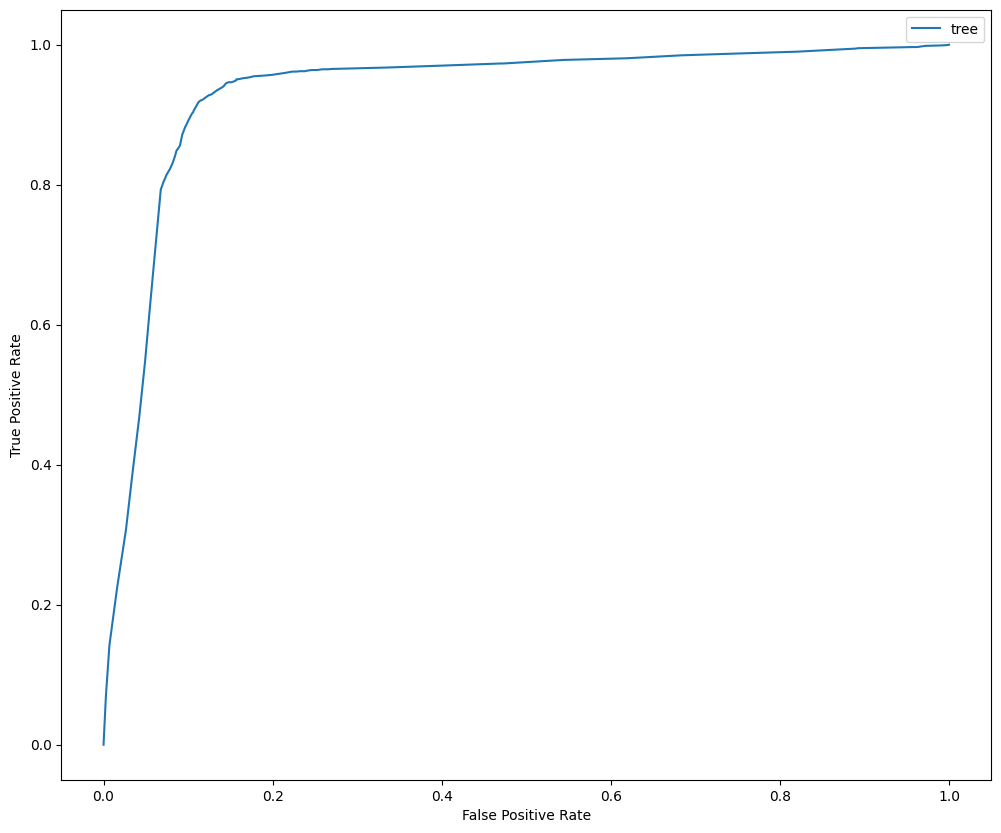

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(tree_fpr, tree_tpr, label="tree")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
tree_auc = auc(tree_fpr, tree_tpr)

# Print results
pd.DataFrame({"Model":['Decision Tree'], "AUC":[tree_auc]})

,Model,AUC
0,Decision Tree,0.932265


In [ ]:
final_test = my_model.predict(X_test_rescale)
final_test

array([0., 0., 0., ..., 0., 1., 0.])

In [ ]:
# evaluate final test result
print("Accuracy:",accuracy_score(y_test_rescale, final_test, normalize=True, sample_weight=None))
print("Confusion Matrix:", '\n', confusion_matrix(y_test_rescale, final_test))

Accuracy: 0.8782991202346041
Confusion Matrix: 
 [[1176  142]
 [  24   22]]


In [ ]:
#The number for bankrupted
np.count_nonzero(y_test_rescale)

46

In [ ]:
#The number for non-bankrupted
np.shape(y_test_rescale)[0]-np.count_nonzero(y_test_rescale)

1318

In [ ]:
#The accuracy of guessing all companies did not go bankrupted
random_guessing_accuracy=1-(np.count_nonzero(y_test_rescale)/(np.shape(y_test_rescale)[0]))

In [ ]:
random_guessing_accuracy

0.966275659824047

In [ ]:
model_accuracy=accuracy_score(y_test_rescale, final_test, normalize=True, sample_weight=None)

In [ ]:
model_accuracy

0.8782991202346041

In [ ]:
if model_accuracy>random_guessing_accuracy:
  print("Good model")
else:
  print("Not bad, but expect better.")

Not bad, but expect better.


In [ ]:
from sklearn import tree
from matplotlib import pyplot as plt

In [ ]:
new_df=pd.read_csv('data.csv')

In [ ]:
fig = plt.figure(figsize=(200,200))
_ = tree.plot_tree(my_model,feature_names=list(new_df)[1:], class_names=['Not Bankrupted','Bankrupted'], max_depth=5,filled=True)

In [ ]:
#Necessary part
#Check the accuracy on testing dataset by using ROC

In [ ]:
new_tree_score = accuracy_score(y_test_rescale, final_test, normalize=True, sample_weight=None)
print(new_tree_score)

0.8782991202346041


In [ ]:
new_tree_preds = final_test

In [ ]:
print (f'This is prediction for decision tree: \n {new_tree_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 0. 1. 0.]


In [ ]:
np.count_nonzero(new_tree_preds==0),np.count_nonzero(new_tree_preds)

(1200, 164)

In [ ]:
print(accuracy_score(y_test_rescale, new_tree_preds, normalize=True, sample_weight=None))

0.8782991202346041


In [ ]:
print(f'This is confusion matrix for decision tree: \n{confusion_matrix(y_test_rescale, new_tree_preds)}')

This is confusion matrix for decision tree: 
[[1176  142]
 [  24   22]]


In [ ]:
new_tree_preds_prob = my_model.predict_proba(X_test_rescale)

In [ ]:
new_tree_preds_prob

array([[0.88555858, 0.11444142],
       [0.96570538, 0.03429462],
       [0.96570538, 0.03429462],
       ...,
       [0.96570538, 0.03429462],
       [0.23488372, 0.76511628],
       [0.96570538, 0.03429462]])

In [ ]:
new_tree_preds_prob_1 = my_model.predict_proba(X_test_rescale)[:,1]

In [ ]:
new_tree_fpr, new_tree_tpr, new_thresholds = roc_curve(y_test_rescale, new_tree_preds_prob_1)

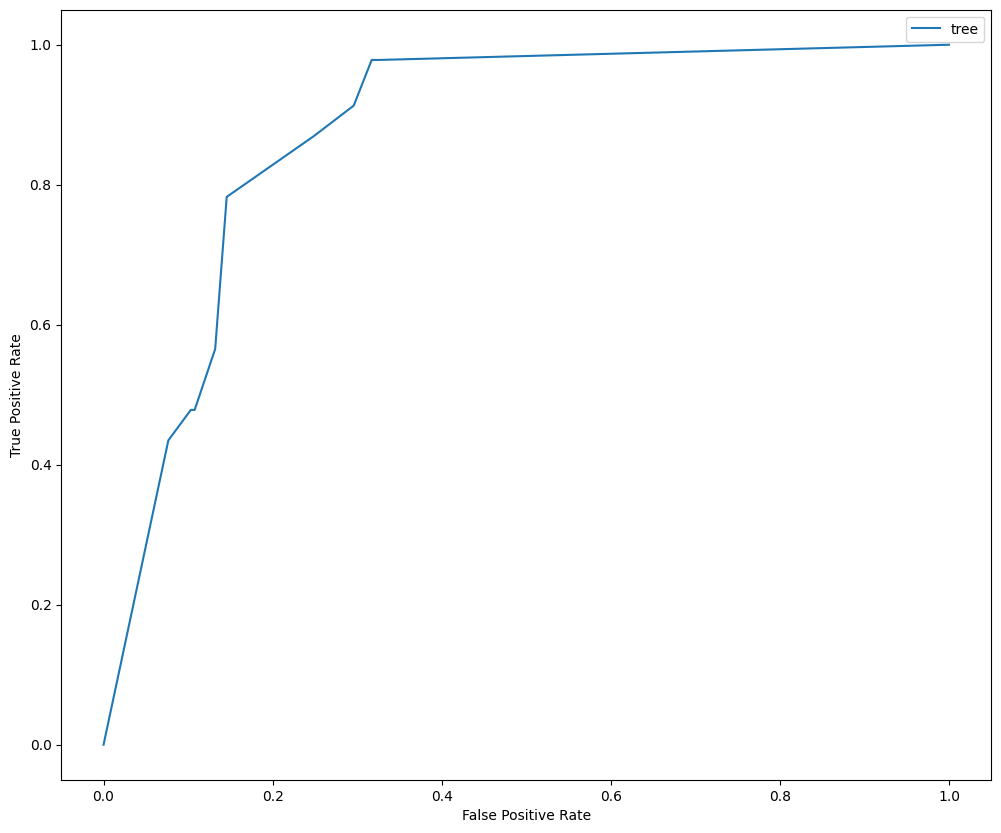

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(new_tree_fpr, new_tree_tpr, label="tree")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
new_tree_auc = auc(new_tree_fpr, new_tree_tpr)

# Print results
pd.DataFrame({"Model":['Decision Tree'], "AUC":[new_tree_auc]})

,Model,AUC
0,Decision Tree,0.875421


In [ ]:
test_confusion_matrix=confusion_matrix(y_test, new_tree_preds)

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.4782608695652174


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(new_tree_preds_prob)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i,1]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1126  192]
 [  10   36]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
print("In investor perspective: Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

In investor perspective: Recall=TP/(TP+FN)=  0.782608695652174


In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 292


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 292.6


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost:", cost-gain)

Net cost: -0.6000000000000227
